In [2]:
from anemone.physics import *
from anemone import constants as c
import torch
import matplotlib.pyplot as plt
import numpy as np

In [3]:
def transverse_electric_field_coefficients(sigma, thickness, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    """ for computing the field components at depth
        the size of the matrix can and should be reduced by 2.
        There are 2*n_layers of equations, but parameters in the first and last layers are known and can therefore be simplified.

    """
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon

    n_layers=len(sigma)

    lambda2 = wave_length**2
    
    u0 = torch.sqrt(lambda2 - omega**2 * c.mu0*c.epsilon0 + 0j)
    
    k2 = calc_wavenumber(sigma, omega, mu=mu, epsilon=epsilon, sqrt=False)

    u_n = torch.sqrt(lambda2 - k2)
    euh_p = torch.exp(u_n[:-1]*thickness)
    euh_m = 1./euh_p

    Amat = torch.zeros(u0.squeeze().shape+(2*n_layers, 2*n_layers), dtype=torch.complex128, device=sigma.device)
    Bmat = torch.zeros((2*n_layers,), dtype=torch.complex128, device=sigma.device)

    Amat[..., 0,0], Amat[..., 0,1], Amat[..., 0,2], Amat[..., 0,3] =  1.,  1.,    -1., -1.
    Amat[..., 1,0], Amat[..., 1,1], Amat[..., 1,2], Amat[..., 1,3] = -u0,  u0, u_n[0], -u_n[0]
    
    for i in range(1, n_layers-1):
        Amat[..., i*2,i*2]   = euh_m[i-1]
        Amat[..., i*2,i*2+1] = euh_p[i-1]
        Amat[..., i*2,i*2+2] = -1.
        Amat[..., i*2,i*2+3] = -1.


        Amat[..., i*2+1,i*2  ] = -u_n[i-1]*euh_m[i-1]
        Amat[..., i*2+1,i*2+1] =  u_n[i-1]*euh_p[i-1]
        Amat[..., i*2+1,i*2+2] =  u_n[i]
        Amat[..., i*2+1,i*2+3] = -u_n[i]

    Amat[..., -2,-1] = 1.
    Amat[..., -1, 0] = 1.

    Bmat[-1] = 1.

    AB = torch.linalg.solve(Amat, Bmat)
    return AB[..., ::2], AB[..., 1::2]

In [36]:
sigma = 10**np.random.uniform(-3, 1, 5)
sigma = torch.from_numpy(sigma).to(torch.float64)
thick = torch.logspace(0.5, 2, len(sigma))[1:]
thick_z = torch.zeros(len(sigma)+1)
thick_z[1:-1] = thick
thick_z[-1] = thick[-1]

# omega = torch.tensor([2000], dtype=torch.float64)
# lamda = torch.tensor([0.1], dtype=torch.float64)

omega = torch.logspace(1,6, 101, dtype=torch.float64)
lamda = torch.logspace(-2,4, 201, dtype=torch.float64)

sigma = sigma[:, None, None].to(torch.complex128)
thick = thick[:, None, None].to(torch.complex128)
# thick_z = thick_z[:,None, None].to(torch.complex128)
omega = omega[None, :, None].to(torch.complex128)
lamda = lamda[None, None, :].to(torch.complex128)


In [37]:
A,B = transverse_electric_field_coefficients(sigma, thick, omega, lamda)

In [38]:
rte = refl_transverse_electric(sigma, thick, omega, lamda)

In [39]:
rte0 = -rte
rteN = -B[..., 0]

C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\1201556403.py:3: RuntimeWarning: invalid value encountered in log10
  pcm = axs[0].pcolor(x,y, np.log10(rteN.real.squeeze()), vmin=-10, vmax=0)
C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\1201556403.py:4: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\1201556403.py:5: RuntimeWarning: invalid value encountered in log10
  pcm = axs[1].pcolor(x,y, np.log10(rte0.real.squeeze()), vmin=-10, vmax=0)
C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\1201556403.py:6: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, a

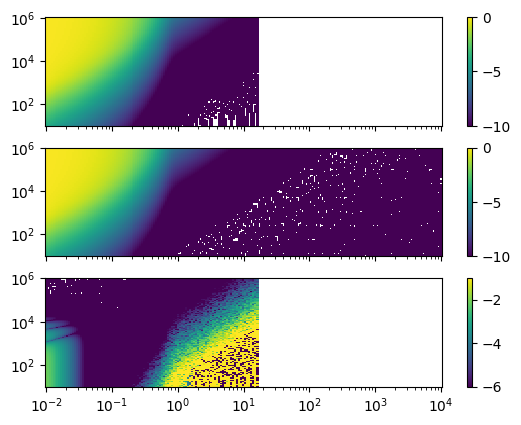

In [43]:
x,y = lamda.squeeze().real, omega.squeeze().real
fig,axs = plt.subplots(3,1, sharex=True, sharey=True)
pcm = axs[0].pcolor(x,y, np.log10(rteN.real.squeeze()), vmin=-10, vmax=0)
plt.colorbar(pcm, ax=axs[0])
pcm = axs[1].pcolor(x,y, np.log10(rte0.real.squeeze()), vmin=-10, vmax=0)
plt.colorbar(pcm, ax=axs[1])
pcm = axs[2].pcolor(x,y, np.log10(np.abs((rteN.real.squeeze()-rte0.real.squeeze())/rte0.real.squeeze())), vmin=-6, vmax=-1)
plt.colorbar(pcm, ax=axs[2])
axs[2].set_xscale('log'); axs[2].set_yscale('log')

C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\193264105.py:4: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[0])
C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\193264105.py:7: RuntimeWarning: divide by zero encountered in log10
  pcm = axs[2].pcolor(x,y, np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1)
C:\Users\au646858\AppData\Local\Temp\ipykernel_22892\193264105.py:8: MatplotlibDeprecationWarning: Getting the array from a PolyQuadMesh will return the full array in the future (uncompressed). To get this behavior now set the PolyQuadMesh with a 2D array .set_array(data2d).
  plt.colorbar(pcm, ax=axs[2])


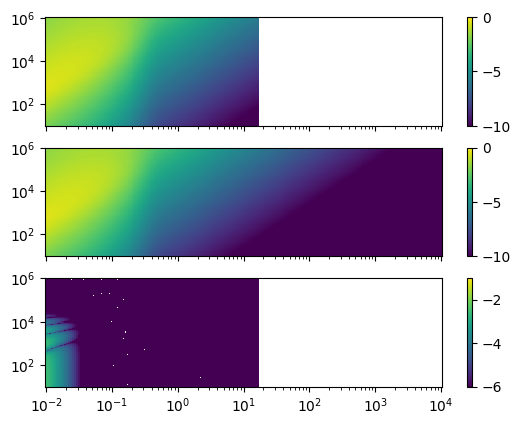

In [42]:
x,y = lamda.squeeze().real, omega.squeeze().real
fig,axs = plt.subplots(3,1, sharex=True, sharey=True)
pcm = axs[0].pcolor(x,y, np.log10(rteN.imag.squeeze()), vmin=-10, vmax=0)
plt.colorbar(pcm, ax=axs[0])
pcm = axs[1].pcolor(x,y, np.log10(rte0.imag.squeeze()), vmin=-10, vmax=0)
plt.colorbar(pcm, ax=axs[1])
pcm = axs[2].pcolor(x,y, np.log10(np.abs((rteN.imag.squeeze()-rte0.imag.squeeze())/rte0.imag.squeeze())), vmin=-6, vmax=-1)
plt.colorbar(pcm, ax=axs[2])
axs[2].set_xscale('log'); axs[2].set_yscale('log')

In [3]:
from anemone.forwards import Forward

class ForwardFD(Forward):
    def __init__(self, source, receiver, freqs, waveform=None, filterfunc=None, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freqs = freqs if isinstance(freqs, torch.Tensor) else torch.tensor(freqs)
        self.device = freqs.device
        self.rmin = self.source.min_horizontal_distance(self.receiver).to(freqs.device)
        self.rmax = self.source.max_horizontal_distance(self.receiver).to(freqs.device)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()[0]
        self.pfield_dz = torch.abs(self.srcz-self.rz)#[:, None, None]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)#[:, None, None]

        self.filterfunc = filterfunc
        self.waveform = waveform
        self.tolerance=tolerance
        if self.device is not None:
            for attr_name in self.__dict__:
                attr_value = getattr(self, attr_name)
                if torch.is_tensor(attr_value):
                    setattr(self, attr_name, attr_value.to(self.device))      

    def forward(self):
        def frq_integrand(f):
            omega = c.twopi*f[:,None]

            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                lmb = wave_length[None, :]
                
                tmp_u0 = u0(omega, lmb)
                A,B = transverse_electric_field_coefficients(self.sigma, self.thick, omega, lmb)
                
                intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
                intg *= lmb**2 / tmp_u0
            
                if self.filterfunc is not None:
                    intg *= self.filterfunc.omega_filter(omega)
                return torch.squeeze(intg/c.fourpi)
            
            hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
            res = integrate_around_loop(self.source, self.receiver, hkl1)
            if self.waveform is not None:
                res /= -1j*omega.squeeze()
            return res.squeeze()
        
        H = frq_integrand(self.freqs)

        if self.waveform is not None:
            return H*self.waveform.fourier_d2wdt2(self.freqs)
        else:
            return H